In [1]:
# Import Dependencies

import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets, linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [2]:
# Load Diabetes dataset
diabetes = datasets.load_diabetes()

# Convert dataset into Pandas DataFrame
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)

# Add target column
df['target'] = diabetes.target

# Display first five records
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
# Display dataset information
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumns:")
print(df.columns)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical description
print("\nStatistical Description:")
print(df.describe())

Dataset Shape: (442, 11)

Columns:
Index(['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6',
       'target'],
      dtype='object')

Missing Values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Statistical Description:
                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02   
min   -1.072256e-01 -4.464164e-02 -9.027530e-02 -1.123988e-01 -1.267807e-01   
25%   -3.729927e-02 -4.464164e-02 -3.422907e-02 -3.665608e-02 -3.424784e-02   
50%    5.383060e-03 -4.464164e-02 -7.283766e-03 -5.670422e-03 -4.320866e-03   
75%    3.807591e-02  5.068012e-02  3.124802e-02  3.564379e-02  2.835801e-02   
max    1.107267e-01  5.068012e-02  

In [4]:
# Separating input features and target

# X - Independent variables
X = df.drop('target', axis=1)     # axis=1 means we are removing a column.

# y - Dependent variable
y = df['target']

print("Independent Variables:")
print(X.head())

print("\nDependent Variable:")
print(y.head())

Independent Variables:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  

Dependent Variable:
0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: target, dtype: float64


In [5]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=1
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (265, 10)
Testing Data: (177, 10)


In [6]:
# Create Linear Regression object
lin_reg = linear_model.LinearRegression()

# Train the model
lin_reg.fit(X_train, y_train)


LinearRegression()

In [7]:
# Predict values for testing data
predicted = lin_reg.predict(X_test)

# Store actual values
expected = y_test

# Create DataFrame for comparison
result = pd.DataFrame({
    'Actual Values': expected.values,
    'Predicted Values': predicted
})

print(result.head(10))

   Actual Values  Predicted Values
0           78.0        121.893187
1          152.0        108.500474
2          200.0        190.612252
3           59.0         64.947294
4          311.0        175.744302
5          178.0        191.226068
6          332.0        224.926332
7          132.0        116.864923
8          156.0        152.345260
9          135.0        124.840982


In [8]:
# R2 Score
r2 = r2_score(y_test, predicted)
print("R2 Score:", r2)

# Mean Squared Error
mse = mean_squared_error(y_test, predicted)
print("Mean Squared Error:", mse)

# Root Mean Squared Error
rmse = np.sqrt(mse)
print("Root Mean Squared Error:", rmse)

# Mean Absolute Error
mae = mean_absolute_error(y_test, predicted)
print("Mean Absolute Error:", mae)

R2 Score: 0.41603976183363156
Mean Squared Error: 2962.953110546192
Root Mean Squared Error: 54.43301489487967
Mean Absolute Error: 43.0581979270872


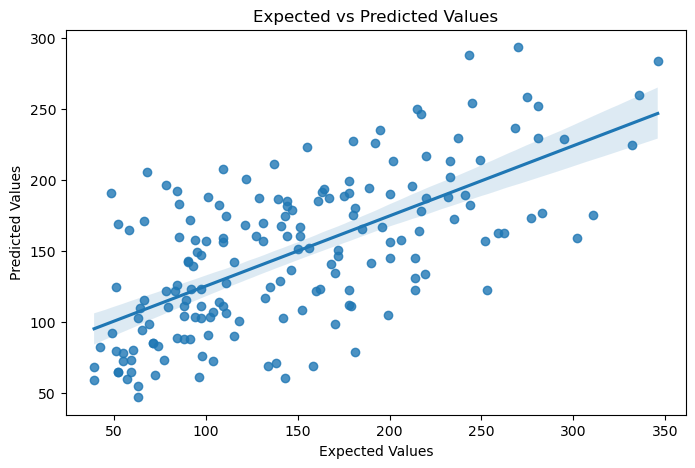

In [9]:
plt.figure(figsize=(8, 5))

sns.regplot(x=expected, y=predicted)

plt.title("Expected vs Predicted Values")
plt.xlabel("Expected Values")
plt.ylabel("Predicted Values")

plt.show()